# 02 — Annual loss simulation

Each simulated year has a random number of claims. We draw a payment
for each claim and add the payments to get the portfolio's total loss
for that year. A year with zero claims has zero loss.

With 50 expected claims per year and a mean payment of CAD 5,000,
the analytical expected annual loss is CAD 250,000. We use that
value to check the simulation.

In [3]:
from pathlib import Path
import sys

import numpy as np

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.simulation import (
    BASELINE,
    simulate_annual_losses,
    summarize_annual_losses,
)

In [2]:
annual_losses = simulate_annual_losses(**BASELINE)

expected_claims = BASELINE["exposure"] * BASELINE["frequency"]
severity_mean = BASELINE["severity_mean"]
severity_std_dev = BASELINE["severity_std_dev"]

expected_loss = expected_claims * severity_mean
simulated_mean = annual_losses.mean()
annual_variance = expected_claims * (severity_std_dev**2 + severity_mean**2)
standard_error = np.sqrt(annual_variance / annual_losses.size)

difference = simulated_mean - expected_loss
within_tolerance = abs(difference) <= 5 * standard_error

print(f"Simulated years:       {annual_losses.size:,}")
print(f"Expected annual loss:  CAD {expected_loss:,.0f}")
print(f"Simulated mean loss:   CAD {simulated_mean:,.0f}")
print(f"Difference:            CAD {difference:+,.0f}")
print(f"Within five standard errors: {within_tolerance}")

Simulated years:       50,000
Expected annual loss:  CAD 250,000
Simulated mean loss:   CAD 250,157
Difference:            CAD +157
Within five standard errors: True


In [4]:
threshold = 350_000
risk = summarize_annual_losses(annual_losses, threshold=threshold)

print(f"Mean annual loss:    CAD {risk['mean']:,.0f}")
print(f"Median annual loss:  CAD {risk['median']:,.0f}")

for confidence in (95, 99):
    print(f"{confidence}% VaR:             CAD {risk[f'var_{confidence}']:,.0f}")
    print(f"{confidence}% TVaR:            CAD {risk[f'tvar_{confidence}']:,.0f}")

print(
    f"Chance of exceeding CAD {threshold:,.0f}: "
    f"{risk['exceedance_probability']:.2%}"
)

Mean annual loss:    CAD 250,157
Median annual loss:  CAD 243,056
95% VaR:             CAD 365,256
95% TVaR:            CAD 408,779
99% VaR:             CAD 433,156
99% TVaR:            CAD 483,911
Chance of exceeding CAD 350,000: 6.96%


### Reading the risk measures

- **95% VaR** is the annual loss level that about 95% of simulated years
  fall at or below.
- **95% TVaR** is the average loss in the worst 5% of simulated years.
- **99% VaR and TVaR** describe the cutoff and average loss for the
  worst 1% of simulated years.
- **Threshold exceedance** is the share of simulated years with losses
  strictly above CAD 350,000.

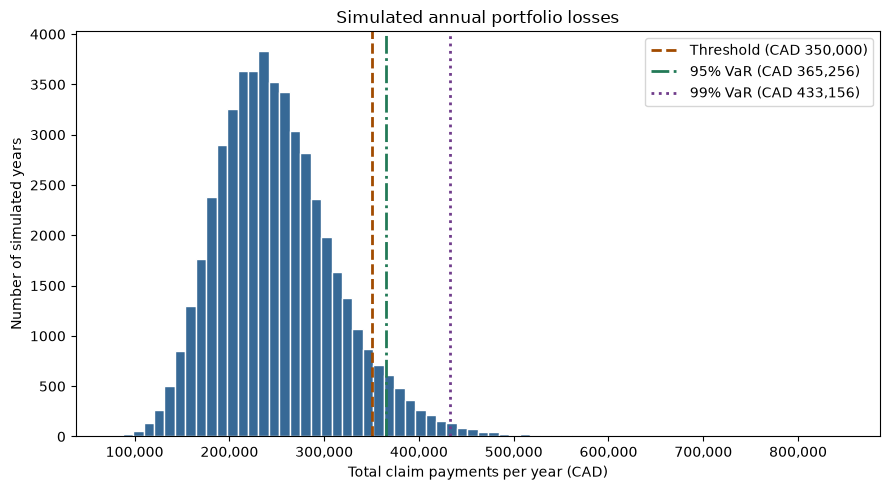

Saved figure to /Users/eloisefang/Downloads/monte-carlo-insurance-risk/figures/annual_loss_distribution.png


In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(annual_losses, bins=70, color="#376996", edgecolor="white")

markers = [
    (threshold, "Threshold", "#a14b00", "--"),
    (risk["var_95"], "95% VaR", "#237a57", "-."),
    (risk["var_99"], "99% VaR", "#703c8b", ":"),
]

for value, label, color, linestyle in markers:
    ax.axvline(
        value,
        color=color,
        linestyle=linestyle,
        linewidth=2,
        label=f"{label} (CAD {value:,.0f})",
    )

ax.set(
    title="Simulated annual portfolio losses",
    xlabel="Total claim payments per year (CAD)",
    ylabel="Number of simulated years",
)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend()
fig.tight_layout()

figures_dir = project_root / "figures"
figures_dir.mkdir(exist_ok=True)
output_path = figures_dir / "annual_loss_distribution.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure to {output_path}")

### Baseline findings

Annual losses exceeded CAD 350,000 in 6.96% of the 50,000 simulated years.
The 99% VaR was CAD 433,156, and the average loss across the worst 1%
of simulated years was CAD 483,911.